#  Post-Harvest Loss Prevention System - End-to-End Machine Learning Pipeline


In [ ]:
import joblib
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, r2_score,
    mean_squared_error, mean_absolute_error
)
print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
BASE_DIR = Path(".")
DATASET_PATH = BASE_DIR / "dataset" / "Produce_Dataset.csv"

df = pd.read_csv(DATASET_PATH)
print(f"Dataset Loaded Successfully! Shape: {df.shape}")
df.head()


Dataset Loaded Successfully! Shape: (100000, 42)


,Record_ID,Category,Produce_Name,Variety,Produce_Grade,Quality_Score,Health_Score,Market_Price,Transport_Mode,Distance_to_Market,...,Weight,Weather,Season,Shelf_Life,Disease_Detected,Sensor_Status,Spoilage_Risk,Recommendation,Alert_Status,Timestamp
0,1,Fruit,Banana,Cavendish,A,99,66,221.90,Truck,553,...,11.92,Cloudy,Winter,4,No,Inactive,High,Immediate sale or processing required.,Critical,2026-06-29 19:43:08
1,2,Fruit,Papaya,Red Lady,B,83,48,88.70,Pickup Van,342,...,12.07,Foggy,Spring,10,Yes,Maintenance,Medium,Improve storage conditions.,Warning,2026-07-06 10:52:44
2,3,Fruit,Pomegranate,Bhagwa,A,79,24,264.99,Container,477,...,16.77,Sunny,Summer,3,Yes,Inactive,High,Immediate sale or processing required.,Critical,2026-02-09 10:17:45
3,4,Vegetable,Cabbage,Green,C,82,74,74.28,Container,252,...,5.94,Foggy,Monsoon,7,No,Inactive,Medium,Improve storage conditions.,Warning,2026-06-23 18:36:56
4,5,Vegetable,Cabbage,Green,A,65,32,165.40,Mini Truck,13,...,17.08,Foggy,Summer,4,No,Inactive,High,Immediate sale or processing required.,Critical,2026-04-18 10:41:19


In [ ]:
print("--- Dataset Information ---")
print(df.info())

print("\n--- Spoilage Risk Distribution ---")
print(df['Spoilage_Risk'].value_    counts())

print("\n--- Summary Statistics ---")
df.describe()


--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 42 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Record_ID             100000 non-null  int64  
 1   Category              100000 non-null  str    
 2   Produce_Name          100000 non-null  str    
 3   Variety               100000 non-null  str    
 4   Produce_Grade         100000 non-null  str    
 5   Quality_Score         100000 non-null  int64  
 6   Health_Score          100000 non-null  int64  
 7   Market_Price          100000 non-null  float64
 8   Transport_Mode        100000 non-null  str    
 9   Distance_to_Market    100000 non-null  int64  
 10  Cold_Chain_Available  100000 non-null  str    
 11  IoT_Device_ID         100000 non-null  str    
 12  Sensor_Battery_Level  100000 non-null  int64  
 13  GPS_Latitude          100000 non-null  float64
 14  GPS_Longitude         100000 non-nul

,Record_ID,Quality_Score,Health_Score,Market_Price,Distance_to_Market,Sensor_Battery_Level,GPS_Latitude,GPS_Longitude,Storage_Cost,Storage_Duration,Temperature,Humidity,Light_Intensity,CO2_Level,Ethylene_Level,Moisture_Content,Weight,Shelf_Life
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,79.994470,51.395190,155.167364,302.345610,70.002310,22.502193,82.514373,260.257802,22.987900,9.140996,89.772726,499.809272,876.586937,5.002716,19.965781,25.447246,10.482980
std,28867.657797,11.837209,18.360258,83.650538,172.425734,17.614126,8.381166,8.352829,138.548669,13.005937,6.186709,8.646950,230.896326,359.589390,2.875289,8.663000,14.133287,6.632723
min,1.000000,60.000000,0.000000,10.000000,5.000000,40.000000,8.000552,68.000289,20.000000,1.000000,0.000000,40.300000,100.000000,250.000000,0.000000,5.000000,1.000000,1.000000
25%,25000.750000,70.000000,39.000000,82.827500,153.000000,55.000000,15.246958,75.277879,140.830000,12.000000,3.700000,87.100000,300.300000,566.400000,2.520000,12.500000,13.230000,6.000000
50%,50000.500000,80.000000,51.000000,155.425000,302.000000,70.000000,22.489880,82.533785,260.460000,23.000000,9.100000,92.100000,500.100000,875.900000,5.000000,20.000000,25.305000,9.000000
75%,75000.250000,90.000000,64.000000,227.550000,452.000000,85.000000,29.749951,89.755770,380.102500,34.000000,13.100000,96.100000,700.000000,1186.900000,7.480000,27.500000,37.650000,12.000000
max,100000.000000,100.000000,100.000000,300.000000,600.000000,100.000000,36.999933,96.999902,499.990000,45.000000,31.800000,98.000000,900.000000,1500.000000,10.000000,35.000000,50.000000,30.000000


In [4]:
DROP_COLUMNS = [
    "Record_ID", "Farmer_ID", "Warehouse_ID", "IoT_Device_ID",
    "Harvest_Date", "Storage_Date", "Timestamp", "Recommendation",
    "Alert_Status"
]

# Features matrix excluding target and metadata leakage columns
df_features = df.drop(columns=DROP_COLUMNS)

# Define Targets
y_clf = df["Spoilage_Risk"]
y_reg = df["Shelf_Life"]

# Exclude targets from feature set X
X = df_features.drop(columns=["Spoilage_Risk", "Shelf_Life"])

# Identify Numerical and Categorical columns
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print(f"Numerical Features ({len(num_cols)}): {num_cols}")
print(f"Categorical Features ({len(cat_cols)}): {cat_cols}")


Numerical Features (16): ['Quality_Score', 'Health_Score', 'Market_Price', 'Distance_to_Market', 'Sensor_Battery_Level', 'GPS_Latitude', 'GPS_Longitude', 'Storage_Cost', 'Storage_Duration', 'Temperature', 'Humidity', 'Light_Intensity', 'CO2_Level', 'Ethylene_Level', 'Moisture_Content', 'Weight']
Categorical Features (15): ['Category', 'Produce_Name', 'Variety', 'Produce_Grade', 'Transport_Mode', 'Cold_Chain_Available', 'Market_Demand', 'State', 'District', 'Storage_Type', 'Package_Type', 'Weather', 'Season', 'Disease_Detected', 'Sensor_Status']


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols)
    ]
)
print("ColumnTransformer preprocessor constructed successfully.")

ColumnTransformer preprocessor constructed successfully.


In [6]:
clf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=100, max_depth=15, min_samples_split=5, random_state=42, n_jobs=-1))
])

X_train, X_test, yclf_train, yclf_test, yreg_train, yreg_test = train_test_split(
    X, y_clf, y_reg, test_size=0.2, random_state=42, stratify=y_clf
)

print("Training Spoilage Risk Classification Pipeline...")
clf_pipeline.fit(X_train, yclf_train)
print("Classification Pipeline Training Completed!")


Training Spoilage Risk Classification Pipeline...


Classification Pipeline Training Completed!


In [ ]:
yclf_pred = clf_pipeline.predict(X_test)

accuracy = accuracy_score(yclf_test, yclf_pred)
precision = precision_score(yclf_test, yclf_pred, average="weighted", zero_division=0)
recall = recall_score(yclf_test, yclf_pred, average="weighted", zero_division=0)
f1 = f1_score(yclf_test, yclf_pred, average="weighted", zero_division=0)

print("CLASSIFICATION METRICS ")
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1 Score : {f1 * 100:.2f}%\n")

print("=== CLASSIFICATION REPORT ===")
print(classification_report(yclf_test, yclf_pred, zero_division=0))


=== CLASSIFICATION METRICS ===
Accuracy : 98.16%
Precision: 98.17%
Recall   : 98.16%
F1 Score : 98.15%

=== CLASSIFICATION REPORT ===


              precision    recall  f1-score   support

        High       0.99      0.96      0.97      3484
         Low       0.99      0.96      0.98      4040
      Medium       0.98      1.00      0.99     12476

    accuracy                           0.98     20000
   macro avg       0.99      0.97      0.98     20000
weighted avg       0.98      0.98      0.98     20000



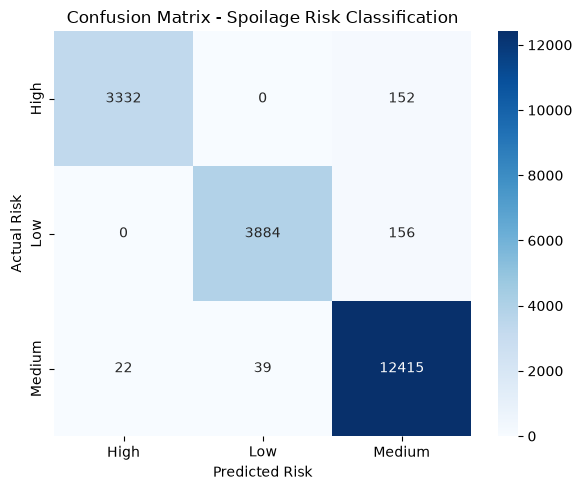

In [8]:
plt.figure(figsize=(6, 5))
cm = confusion_matrix(yclf_test, yclf_pred, labels=clf_pipeline.classes_)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=clf_pipeline.classes_, yticklabels=clf_pipeline.classes_)
plt.title("Confusion Matrix - Spoilage Risk Classification")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.tight_layout()
plt.show()


In [9]:
reg_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_split=5, random_state=42, n_jobs=-1))
])

print("Training Shelf Life Regression Pipeline...")
reg_pipeline.fit(X_train, yreg_train)
print("Regression Pipeline Training Completed!")


Training Shelf Life Regression Pipeline...


Regression Pipeline Training Completed!


In [10]:
yreg_pred = reg_pipeline.predict(X_test)

r2 = r2_score(yreg_test, yreg_pred)
mae = mean_absolute_error(yreg_test, yreg_pred)
rmse = np.sqrt(mean_squared_error(yreg_test, yreg_pred))

print("=== REGRESSION METRICS ===")
print(f"R² Score: {r2:.4f}")
print(f"MAE     : {mae:.2f} days")
print(f"RMSE    : {rmse:.2f} days")


=== REGRESSION METRICS ===
R² Score: 0.8039
MAE     : 2.23 days
RMSE    : 2.92 days


C:\Users\DELL\AppData\Local\Temp\ipykernel_10956\843433470.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df.head(15), x="Importance", y="Feature", palette="viridis")


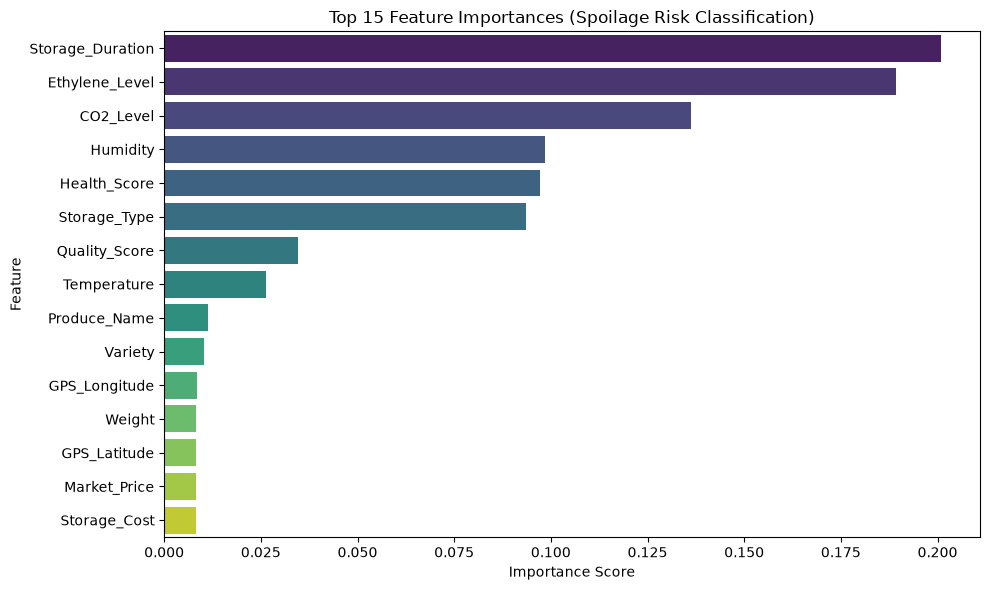

In [11]:
rf_model = clf_pipeline.named_steps["classifier"]
feature_names = num_cols + cat_cols
importances = rf_model.feature_importances_

fi_df = pd.DataFrame({"Feature": feature_names, "Importance": importances}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=fi_df.head(15), x="Importance", y="Feature", palette="viridis")
plt.title("Top 15 Feature Importances (Spoilage Risk Classification)")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [12]:
MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

# 1. Classification Pipeline Artifact
clf_model_path = MODEL_DIR / "spoilage_risk_pipeline.pkl"
best_model_path = MODEL_DIR / "best_model.pkl"

joblib.dump(clf_pipeline, clf_model_path)
joblib.dump(clf_pipeline, best_model_path)

# 2. Regression Pipeline Artifact
reg_model_path = MODEL_DIR / "shelf_life_pipeline.pkl"
joblib.dump(reg_pipeline, reg_model_path)

print(f"Classification Pipeline Saved: {clf_model_path}")
print(f"Regression Pipeline Saved    : {reg_model_path}")
print(f"Alias 'best_model.pkl' Saved : {best_model_path}")
print("\nAll ML operations completed! Exactly 2 primary PKL files generated.")


Classification Pipeline Saved: models\spoilage_risk_pipeline.pkl
Regression Pipeline Saved    : models\shelf_life_pipeline.pkl
Alias 'best_model.pkl' Saved : models\best_model.pkl

All ML operations completed! Exactly 2 primary PKL files generated.


In [13]:
sample_record = X_test.iloc[[0]]
predicted_risk = clf_pipeline.predict(sample_record)[0]
predicted_shelf_life = reg_pipeline.predict(sample_record)[0]

print("--- Sample Inference Demo ---")
print("Input Features:")
print(sample_record[["Category", "Produce_Name", "Temperature", "Humidity", "Storage_Duration"]].to_string())
print(f"\nPredicted Spoilage Risk : {predicted_risk}")
print(f"Predicted Shelf Life    : {predicted_shelf_life:.1f} days")


--- Sample Inference Demo ---
Input Features:
        Category Produce_Name  Temperature  Humidity  Storage_Duration
36635  Vegetable       Potato          9.3      91.8                24

Predicted Spoilage Risk : Medium
Predicted Shelf Life    : 9.3 days


In [ ]:
# STREAMLIT CONNECTION CELL
# This cell saves training_report.json and active_model.json
# so the Streamlit app automatically reads updated model info.
# Run this cell AFTER all training cells have been executed.

import json
from datetime import datetime
from sklearn.metrics import classification_report as _clf_report

trained_at = datetime.now().strftime('%d-%m-%Y %H:%M:%S')

# Full classification report as dict
_cr_dict = _clf_report(yclf_test, yclf_pred, output_dict=True, zero_division=0)

# Keep only per-class rows (exclude macro avg, weighted avg, accuracy)
_class_report = {
    cls: {
        'precision': round(_cr_dict[cls]['precision'], 4),
        'recall':    round(_cr_dict[cls]['recall'],    4),
        'f1-score':  round(_cr_dict[cls]['f1-score'],  4),
        'support':   int(_cr_dict[cls]['support'])
    }
    for cls in clf_pipeline.classes_
    if cls in _cr_dict
}

# ── training_report.json 
training_report = {
    'dataset_name':      'Produce_Dataset.csv',
    'dataset_rows':      len(df),
    'dataset_columns':   len(df.columns),
    'training_rows':     len(X_train),
    'test_rows':         len(X_test),
    'target_column':     'Spoilage_Risk',
    'best_model':        'Random Forest',
    'accuracy':          round(accuracy  * 100, 2),
    'precision':         round(precision * 100, 2),
    'recall':            round(recall    * 100, 2),
    'f1_score':          round(f1        * 100, 2),
    'results': {
        'Random Forest Spoilage Risk': round(accuracy * 100, 2),
        'Random Forest Shelf Life R2': round(r2 * 100, 2)
    },
    'classification_report': _class_report,
    'shelf_life_metrics': {
        'r2_score':  round(r2,   4),
        'mae_days':  round(mae,  2),
        'rmse_days': round(rmse, 2)
    },
    'model_params': {
        'n_estimators':     100,
        'max_depth':        15,
        'min_samples_split': 5,
        'random_state':     42
    },
    'features_used': len(X_train.columns),
    'trained_at':    trained_at,
    'pipeline_source': 'post_harvest_ml_pipeline.ipynb'
}

report_path = MODEL_DIR / 'training_report.json'
with open(report_path, 'w') as f:
    json.dump(training_report, f, indent=4)
print(f'training_report.json saved  -> {report_path}')

# ── active_model.json 
active_model = {
    'model_type':             'pipeline',
    'model_status':           'active',
    'model_file':             'spoilage_risk_pipeline.pkl',
    'shelf_life_model_file':  'shelf_life_pipeline.pkl',
    'best_model_alias':       'best_model.pkl',
    'dataset_name':           'Produce_Dataset.csv',
    'target_column':          'Spoilage_Risk',
    'best_model':             'Random Forest',
    'accuracy':               round(accuracy  * 100, 2),
    'precision':              round(precision * 100, 2),
    'recall':                 round(recall    * 100, 2),
    'f1_score':               round(f1        * 100, 2),
    'shelf_life_r2':          round(r2,   4),
    'shelf_life_mae':         round(mae,  2),
    'shelf_life_rmse':        round(rmse, 2),
    'trained_at':             trained_at,
    'pipeline_source':        'post_harvest_ml_pipeline.ipynb',
    'notes':                  f'Trained on {len(X_train)} records with {len(X_train.columns)} features'
}

active_path = MODEL_DIR / 'active_model.json'
with open(active_path, 'w') as f:
    json.dump(active_model, f, indent=4)
print(f'active_model.json  saved  -> {active_path}')

print('\n✅ Streamlit Connection Complete!')
print('   Restart your Streamlit app to load the updated metrics.')
